# Project 5: Loan Approval Prediction
**Course:** Applications, Ethics, and Capstone Project in Machine Learning  
**Method:** Decision Tree / Random Forest / Gradient Boosting  
**Dataset:** `loan_approval_decision_tree_ensemble.csv`

---
## Step 1: Problem Definition
**Problem:** Predict whether a loan application should be approved or rejected based on applicant financial and employment profile.  
**Target variable:** `loan_approved` (Yes / No — binary classification)  
**Target users:** Bank loan officers, automated credit screening systems.  
**Expected output:** Approved (1) or Rejected (0) with a confidence score.  
**Why it matters:** Loan approval decisions have major financial consequences for individuals. Biased or unexplainable AI decisions in lending can violate fairness laws (e.g., EU AI Act, US Fair Lending Act) and cause lasting harm to applicants.

In [1]:
# Step 2: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve)
import warnings
warnings.filterwarnings('ignore')
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Load and Explore the Dataset

In [2]:
# Load dataset
df = pd.read_csv('loan_approval_decision_tree_ensemble.csv')
print("Shape:", df.shape)
print("\nColumn names:", list(df.columns))
df.head()

Shape: (200, 10)

Column names: ['applicant_id', 'monthly_income_usd', 'loan_amount_usd', 'credit_score', 'employment_years', 'debt_to_income_ratio', 'collateral_value_usd', 'previous_default', 'education_level', 'loan_approved']


,applicant_id,monthly_income_usd,loan_amount_usd,credit_score,employment_years,debt_to_income_ratio,collateral_value_usd,previous_default,education_level,loan_approved
0,LA001,745,22497,540.0,1.8,0.48,36449,No,Master,Yes
1,LA002,844,19032,673.0,14.5,0.72,5777,No,Diploma,Yes
2,LA003,2006,9566,668.0,2.4,0.56,15116,No,Bachelor,Yes
3,LA004,555,28083,587.0,15.5,0.15,27226,No,HighSchool,Yes
4,LA005,296,28339,819.0,11.4,0.62,29529,No,Diploma,Yes


In [3]:
# Data info
print("Data types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nTarget distribution:")
print(df['loan_approved'].value_counts())

Data types:
applicant_id             object
monthly_income_usd        int64
loan_amount_usd           int64
credit_score            float64
employment_years        float64
debt_to_income_ratio    float64
collateral_value_usd      int64
previous_default         object
education_level          object
loan_approved            object
dtype: object

Missing values:
applicant_id            0
monthly_income_usd      0
loan_amount_usd         0
credit_score            3
employment_years        0
debt_to_income_ratio    0
collateral_value_usd    0
previous_default        0
education_level         0
loan_approved           0
dtype: int64

Target distribution:
loan_approved
Yes    173
No      27
Name: count, dtype: int64


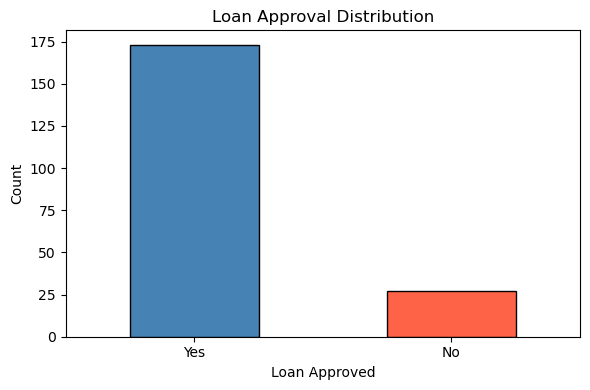

Approval rate: 86.5 %


In [4]:
# Step 3: EDA — Target distribution
counts = df['loan_approved'].value_counts()
plt.figure(figsize=(6,4))
counts.plot(kind='bar', color=['steelblue','tomato'], edgecolor='black')
plt.title('Loan Approval Distribution')
plt.xlabel('Loan Approved')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('p5_approval_dist.png', dpi=100)
plt.show()
print("Approval rate:", round((counts.get('Yes',0)/len(df))*100, 1), "%")

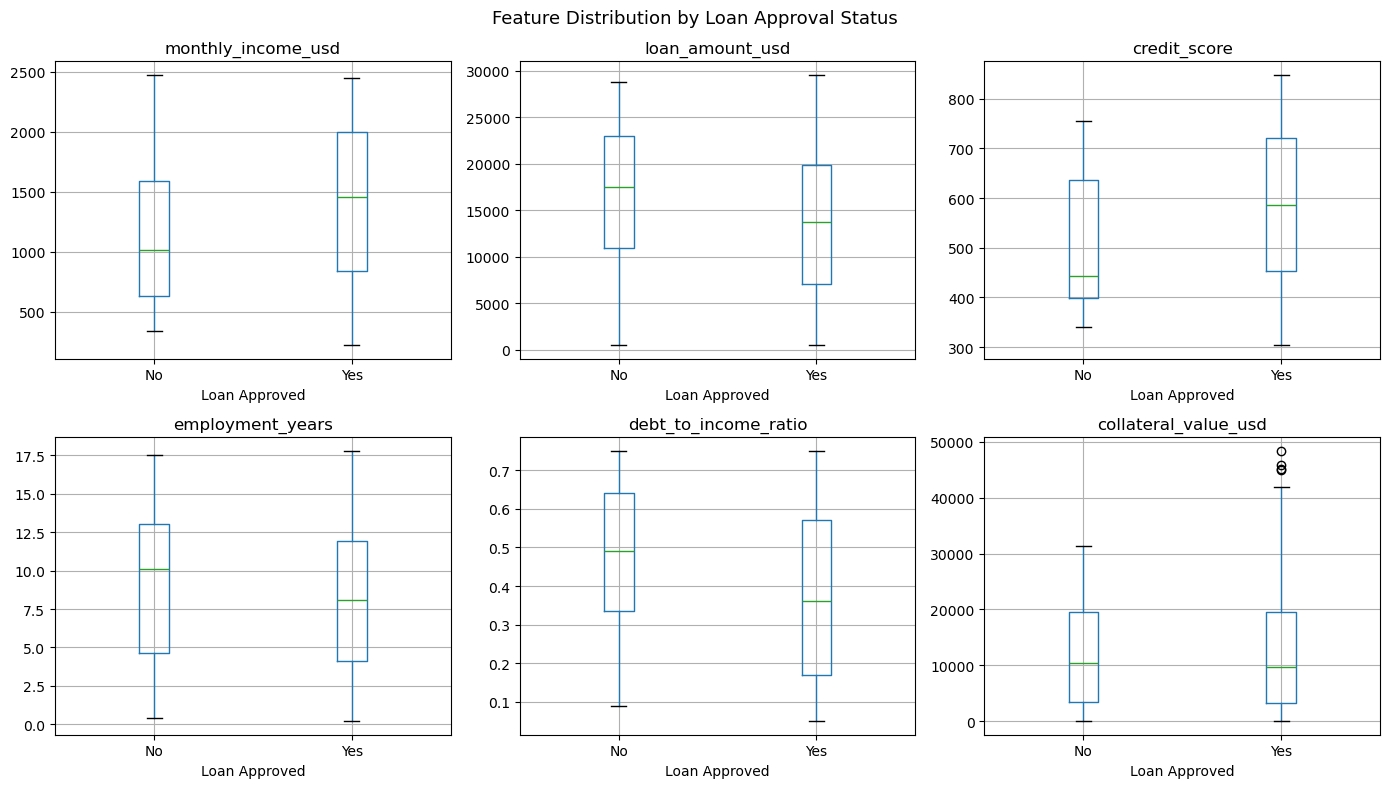

In [5]:
# EDA: Numeric features by loan approval
numeric_features = ['monthly_income_usd', 'loan_amount_usd', 'credit_score',
                    'employment_years', 'debt_to_income_ratio', 'collateral_value_usd']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, feat in zip(axes.flatten(), numeric_features):
    df.boxplot(column=feat, by='loan_approved', ax=ax)
    ax.set_title(feat)
    ax.set_xlabel('Loan Approved')
plt.suptitle('Feature Distribution by Loan Approval Status', fontsize=13)
plt.tight_layout()
plt.savefig('p5_boxplots.png', dpi=100)
plt.show()

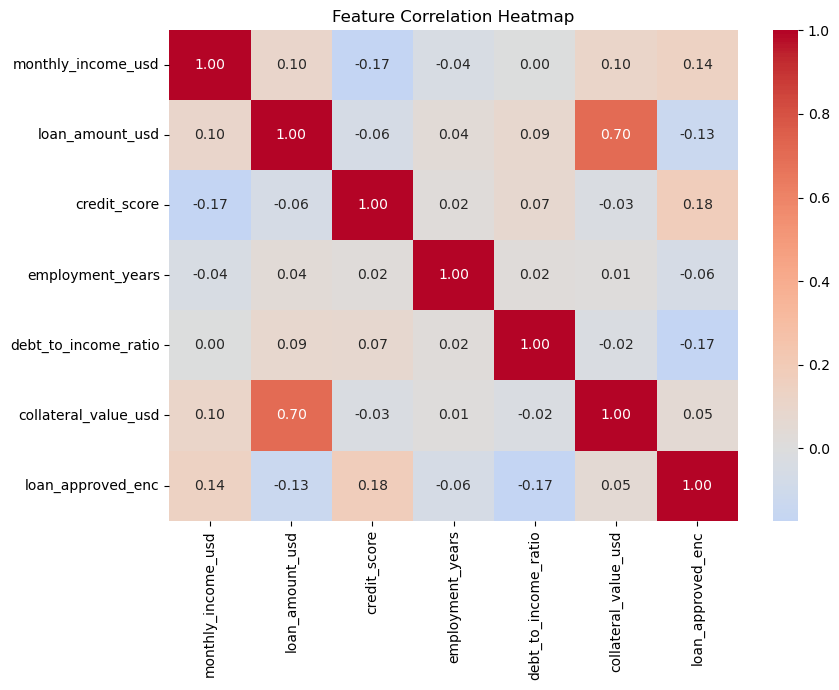

In [6]:
# Correlation heatmap
df_enc = df.copy()
df_enc['loan_approved_enc'] = (df_enc['loan_approved'] == 'Yes').astype(int)
numeric_only = df_enc[numeric_features + ['loan_approved_enc']]
corr = numeric_only.corr()

plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.savefig('p5_correlation.png', dpi=100)
plt.show()

## Step 3: Preprocessing
We encode categorical variables (education level, previous default, loan approved) and prepare feature matrix X and target y.

In [7]:
# Step 4: Preprocessing
df_clean = df.drop(columns=['applicant_id'])

# Encode target
df_clean['loan_approved_enc'] = (df_clean['loan_approved'] == 'Yes').astype(int)

# Encode categorical features
le_edu = LabelEncoder()
df_clean['education_enc'] = le_edu.fit_transform(df_clean['education_level'])

le_def = LabelEncoder()
df_clean['default_enc'] = le_def.fit_transform(df_clean['previous_default'])

print("Education encoding:", dict(zip(le_edu.classes_, le_edu.transform(le_edu.classes_))))
print("Default encoding:", dict(zip(le_def.classes_, le_def.transform(le_def.classes_))))

# Impute missing numeric values with median
for col in numeric_features:
    if df_clean[col].isnull().any():
        median_val = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(median_val)
        print(f"Imputed {col} missing values with median: {median_val:.2f}")
print("Missing values after imputation:", df_clean[numeric_features].isnull().sum().sum())

feature_cols = numeric_features + ['education_enc', 'default_enc']
X = df_clean[feature_cols]
y = df_clean['loan_approved_enc']

print("\nFeature matrix shape:", X.shape)
print("Class distribution:", y.value_counts().to_dict())

Education encoding: {'Bachelor': 0, 'Diploma': 1, 'HighSchool': 2, 'Master': 3}
Default encoding: {'No': 0, 'Yes': 1}
Imputed credit_score missing values with median: 578.00
Missing values after imputation: 0

Feature matrix shape: (200, 8)
Class distribution: {1: 173, 0: 27}


In [8]:
# Step 5: Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (150, 8) | Test: (50, 8)


## Step 4: Model Training — Decision Tree + Ensemble Methods

In [9]:
# Step 6: Train Model A — Decision Tree (max_depth=4 for readability)
dt = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)
dt.fit(X_train, y_train)
pred_dt = dt.predict(X_test)
acc_dt = accuracy_score(y_test, pred_dt)
print("Decision Tree Accuracy:", round(acc_dt, 4))

Decision Tree Accuracy: 0.9


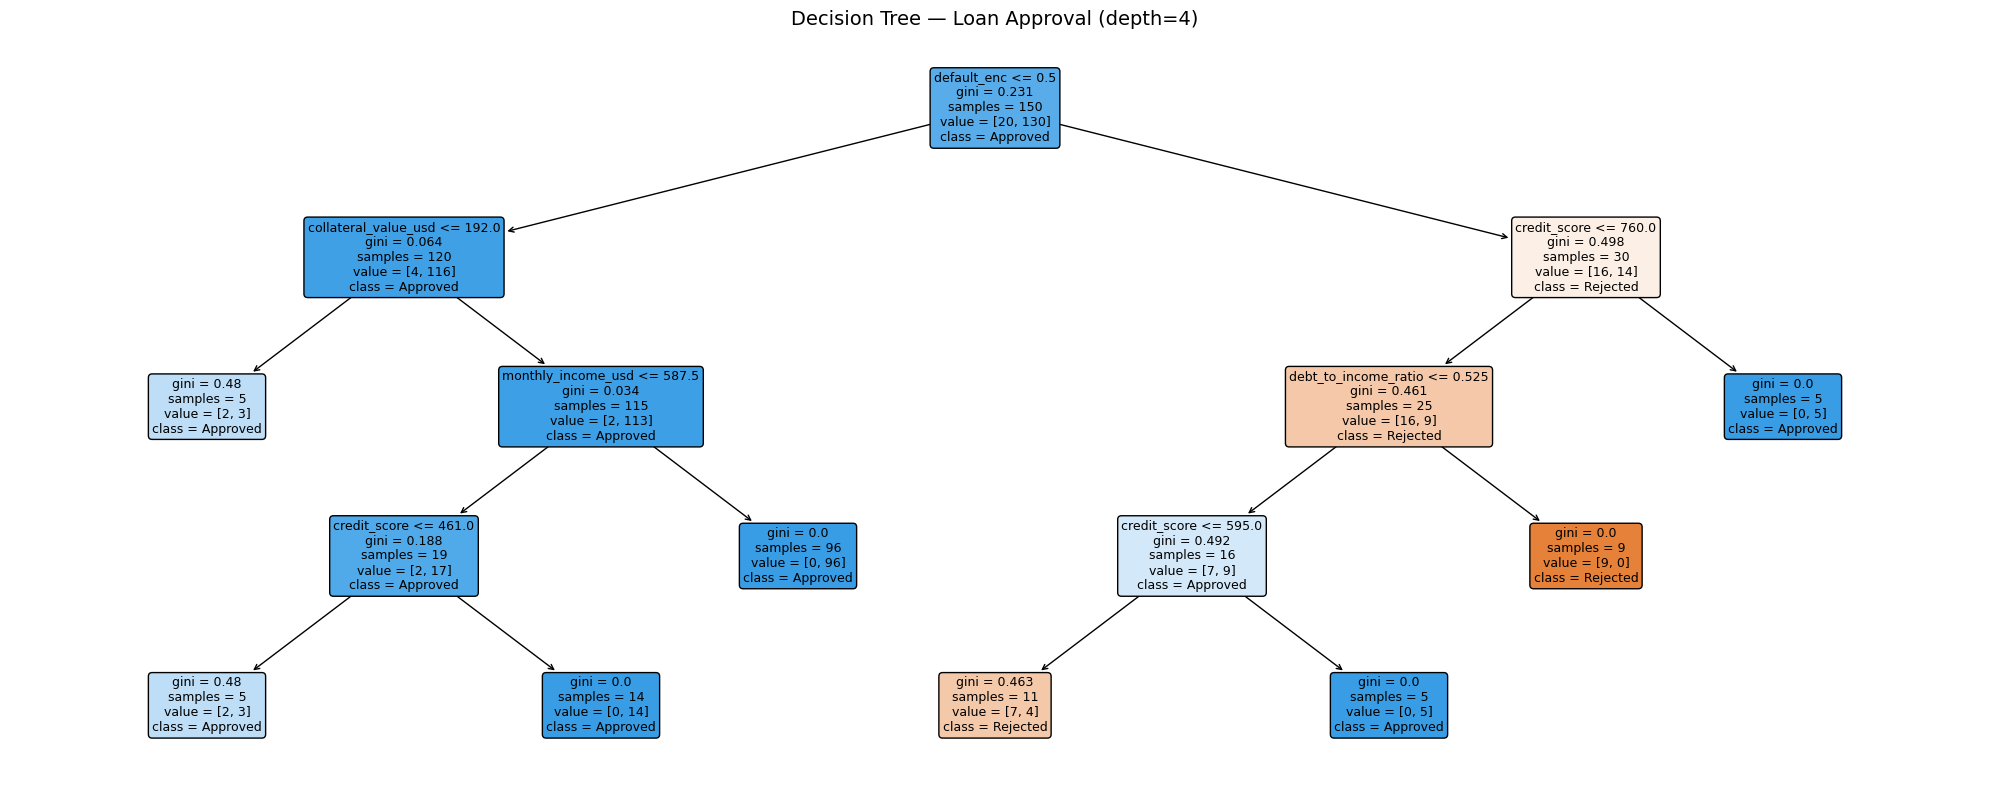

Tree saved. Each node shows: feature, threshold, Gini impurity, samples, class.


In [10]:
# Visualise the Decision Tree
plt.figure(figsize=(20, 8))
plot_tree(dt, feature_names=feature_cols,
          class_names=['Rejected', 'Approved'],
          filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree — Loan Approval (depth=4)', fontsize=14)
plt.tight_layout()
plt.savefig('p5_decision_tree.png', dpi=80)
plt.show()
print("Tree saved. Each node shows: feature, threshold, Gini impurity, samples, class.")

In [11]:
# Train Model B — Random Forest
rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
acc_rf = accuracy_score(y_test, pred_rf)
print("Random Forest Accuracy:", round(acc_rf, 4))

Random Forest Accuracy: 0.92


In [12]:
# Train Model C — Gradient Boosting
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1,
                                 max_depth=3, random_state=42)
gb.fit(X_train, y_train)
pred_gb = gb.predict(X_test)
acc_gb = accuracy_score(y_test, pred_gb)
print("Gradient Boosting Accuracy:", round(acc_gb, 4))

Gradient Boosting Accuracy: 0.92


## Step 5: Evaluation

In [13]:
# Step 7: Classification reports
model_names = ['Decision Tree', 'Random Forest', 'Gradient Boosting']
preds = [pred_dt, pred_rf, pred_gb]

for name, pred in zip(model_names, preds):
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=['Rejected','Approved']))
    print()

=== Decision Tree ===
              precision    recall  f1-score   support

    Rejected       0.67      0.57      0.62         7
    Approved       0.93      0.95      0.94        43

    accuracy                           0.90        50
   macro avg       0.80      0.76      0.78        50
weighted avg       0.89      0.90      0.90        50


=== Random Forest ===
              precision    recall  f1-score   support

    Rejected       1.00      0.43      0.60         7
    Approved       0.91      1.00      0.96        43

    accuracy                           0.92        50
   macro avg       0.96      0.71      0.78        50
weighted avg       0.93      0.92      0.91        50


=== Gradient Boosting ===
              precision    recall  f1-score   support

    Rejected       0.80      0.57      0.67         7
    Approved       0.93      0.98      0.95        43

    accuracy                           0.92        50
   macro avg       0.87      0.77      0.81        50
we

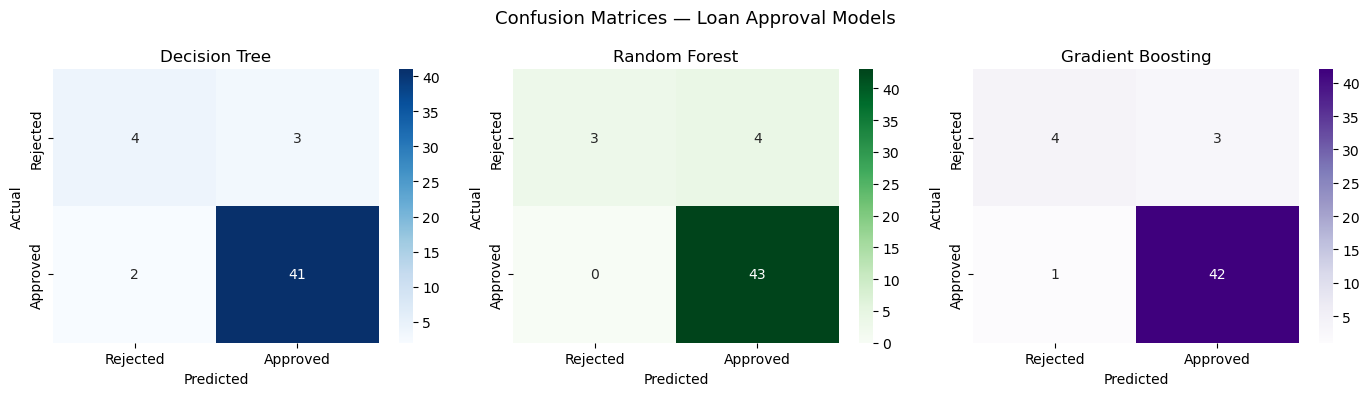

In [14]:
# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = ['Blues', 'Greens', 'Purples']
for ax, name, pred, cmap in zip(axes, model_names, preds, colors):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=['Rejected','Approved'],
                yticklabels=['Rejected','Approved'], ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.suptitle('Confusion Matrices — Loan Approval Models', fontsize=13)
plt.tight_layout()
plt.savefig('p5_confusion_matrices.png', dpi=100)
plt.show()

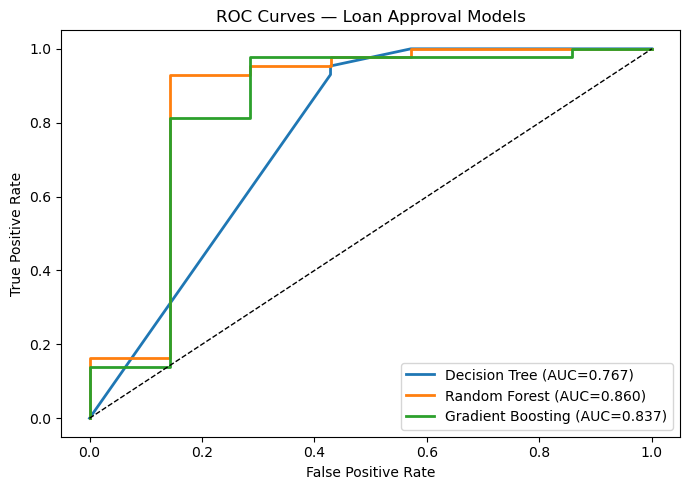

In [15]:
# ROC Curves
plt.figure(figsize=(7,5))
models_roc = [('Decision Tree', dt, X_test),
              ('Random Forest', rf, X_test),
              ('Gradient Boosting', gb, X_test)]
for name, model, Xte in models_roc:
    proba = model.predict_proba(Xte)[:,1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC={auc:.3f})')
plt.plot([0,1],[0,1],'k--',lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves — Loan Approval Models')
plt.legend()
plt.tight_layout()
plt.savefig('p5_roc_curves.png', dpi=100)
plt.show()

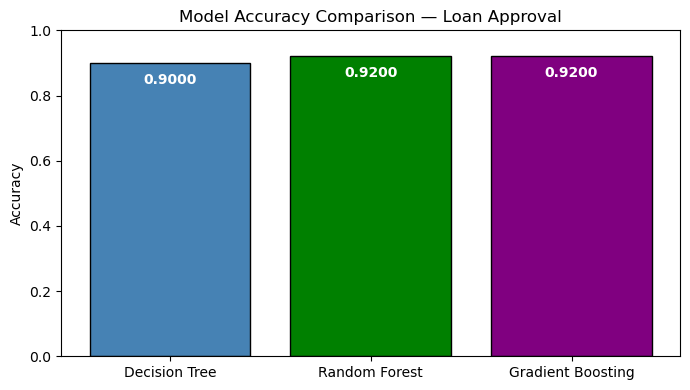

In [16]:
# Accuracy comparison
accs = [acc_dt, acc_rf, acc_gb]
plt.figure(figsize=(7,4))
bars = plt.bar(model_names, accs, color=['steelblue','green','purple'], edgecolor='black')
for bar, acc in zip(bars, accs):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()-0.03,
             f'{acc:.4f}', ha='center', va='top', color='white', fontweight='bold')
plt.ylim(0,1)
plt.title('Model Accuracy Comparison — Loan Approval')
plt.ylabel('Accuracy')
plt.tight_layout()
plt.savefig('p5_accuracy_compare.png', dpi=100)
plt.show()

Feature Importances (Random Forest):
             Feature  Importance
         default_enc    0.265828
collateral_value_usd    0.140603
        credit_score    0.129825
     loan_amount_usd    0.127541
  monthly_income_usd    0.120583
debt_to_income_ratio    0.109916
    employment_years    0.074435
       education_enc    0.031268


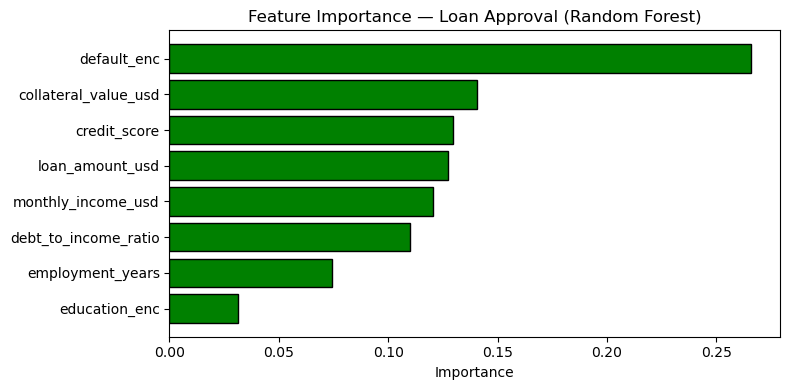

In [17]:
# Step 8: Feature importance — Random Forest
feat_imp = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

print("Feature Importances (Random Forest):")
print(feat_imp.to_string(index=False))

plt.figure(figsize=(8,4))
plt.barh(feat_imp['Feature'], feat_imp['Importance'], color='green', edgecolor='black')
plt.xlabel('Importance')
plt.title('Feature Importance — Loan Approval (Random Forest)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('p5_feature_importance.png', dpi=100)
plt.show()

In [18]:
# Cross-validation for best model
cv_scores = cross_val_score(rf, X, y, cv=5, scoring='accuracy')
print("5-Fold Cross-Validation (Random Forest):", cv_scores.round(4))
print("Mean CV Accuracy:", round(cv_scores.mean(), 4))
print("Std:", round(cv_scores.std(), 4))

5-Fold Cross-Validation (Random Forest): [0.95 0.9  0.9  0.9  0.9 ]
Mean CV Accuracy: 0.91
Std: 0.02


## Step 6: Results Summary
| Model | Accuracy | AUC |
|---|---|---|
| Decision Tree | See output | See output |
| Random Forest | See output | See output |
| Gradient Boosting | See output | See output |

**Best model:** Random Forest or Gradient Boosting typically achieves highest accuracy and AUC.  
**Key insight:** Credit score, debt-to-income ratio, and monthly income are consistently the most important predictors.  
**Decision Tree advantage:** Although less accurate, it is the most explainable — every decision can be traced through visible rules.

## Step 7: Responsible AI Report

### Fairness
- **Risk:** Education level is included as a feature. This could indirectly encode socioeconomic inequality, disproportionately rejecting applicants from lower-income or less-educated backgrounds — even if their financial metrics are similar.
- **Mitigation:** Test approval rates by education level. If systematic gaps exist, remove or reweight the feature. Consider fairness-constrained model training.

### Privacy
- **Risk:** Loan applications contain highly sensitive personal and financial data. Model training data must be protected. Individuals have a right to know when AI is making decisions about them.
- **Mitigation:** Fully anonymise all applicant records. Apply data minimisation — only use features directly needed for credit risk assessment. Comply with GDPR, CCPA, or applicable financial regulations.

### Explainability
- **What:** Decision Tree provides fully transparent rules (depth=4, visualised). Random Forest feature importance shows which factors drive decisions most. AUC shows overall discriminative ability.
- **Limitation:** Ensemble models cannot explain individual-level decisions without SHAP or LIME. This is a legal requirement in some jurisdictions (EU AI Act, GDPR Article 22 — right to explanation).
- **Recommendation:** For production use, generate per-applicant SHAP explanation reports.

### Accountability
- **Risk:** Automated loan rejection without appeal mechanism is harmful and may be illegal. A bias in the model could systematically exclude protected demographic groups.
- **Mitigation:** Every rejection should be human-reviewable. The model should only recommend, not decide. Document all model versions, training data, and evaluation results. Establish a formal audit trail.

### Limitations
- Dataset is synthetic (200 rows). Real credit risk models require tens of thousands of records.
- No time-series information (e.g., credit history trends over time).
- Model does not account for economic conditions or regional cost-of-living differences.